# Violence Detection in Video Clips (CNN + LSTM)

Classifies short video clips as **Violence** or **Non-violence**.

**Pipeline:** sample 16 frames per video (OpenCV) -> extract features per frame with a pretrained **MobileNetV2** (CNN) -> learn the pattern over time with an **LSTM** (RNN) -> evaluate.

**Before you start:** in Colab, go to Runtime > Change runtime type > select a **T4 GPU**. Then run the cells from top to bottom.

In [7]:
!pip install -q kagglehub opencv-python-headless tqdm

In [8]:
import os, random, cv2, numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from tqdm import tqdm

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

N_FRAMES = 16          # frames sampled per video
MAX_PER_CLASS = 300    # videos used per class (raise to 1000 if you have time)
print("TensorFlow:", tf.__version__)
print("GPU found:", len(tf.config.list_physical_devices('GPU')) > 0)

TensorFlow: 2.20.0
GPU found: True


## 1. Download the dataset
Uses the public Kaggle dataset *Real Life Violence Situations*. If this cell fails, download the dataset manually from Kaggle, upload it to Colab (or Google Drive), and set `DATA_DIR` to its folder.

In [9]:
import kagglehub
DATA_DIR = kagglehub.dataset_download("mohamedmustafa/real-life-violence-situations-dataset")
print("Dataset folder:", DATA_DIR)

Using Colab cache for faster access to the 'real-life-violence-situations-dataset' dataset.
Dataset folder: /kaggle/input/real-life-violence-situations-dataset


## 2. Find the videos and their labels

In [10]:
video_paths, labels = [], []
for root, _, files in os.walk(DATA_DIR):
    for f in files:
        if f.lower().endswith((".mp4", ".avi", ".mov", ".mkv")):
            full = os.path.join(root, f)
            folder = os.path.basename(root).lower()
            # check "nonviolence" first because it also contains the word "violence"
            if "nonviolence" in folder or "non_violence" in folder or "non-violence" in folder:
                video_paths.append(full); labels.append(0)
            elif "violence" in folder:
                video_paths.append(full); labels.append(1)

video_paths, labels = np.array(video_paths), np.array(labels)
print("Total videos found:", len(video_paths))
print("Violence:", int((labels == 1).sum()), "| Non-violence:", int((labels == 0).sum()))

# Keep a balanced subset so everything runs quickly
rng = np.random.default_rng(SEED)
keep = []
for cls in (0, 1):
    idx = np.where(labels == cls)[0]
    rng.shuffle(idx)
    keep.extend(idx[:MAX_PER_CLASS])
keep = np.array(keep)
video_paths, labels = video_paths[keep], labels[keep]
print("Using:", len(video_paths), "videos")

Total videos found: 4000
Violence: 2000 | Non-violence: 2000
Using: 600 videos


## 3. Read frames from each video with OpenCV

One video -> (16, 224, 224, 3)


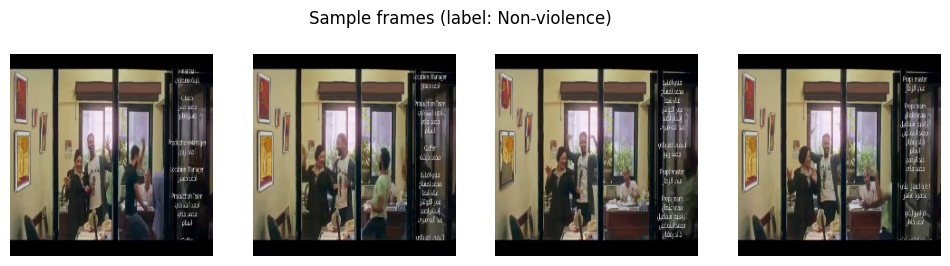

In [11]:
def load_frames(path, n=N_FRAMES):
    cap = cv2.VideoCapture(path)
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total < 1:
        cap.release(); return None
    idxs = np.linspace(0, total - 1, n).astype(int)   # evenly spaced frames
    frames = []
    for i in idxs:
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
        ok, frame = cap.read()
        if not ok:
            continue
        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        frame = cv2.resize(frame, (224, 224))
        frames.append(frame)
    cap.release()
    if len(frames) == 0:
        return None
    while len(frames) < n:          # pad short videos by repeating the last frame
        frames.append(frames[-1])
    return np.array(frames, dtype=np.float32)

# Quick check on one video
test_frames = load_frames(video_paths[0])
print("One video ->", test_frames.shape)
plt.figure(figsize=(12, 3))
for k in range(4):
    plt.subplot(1, 4, k + 1); plt.imshow(test_frames[k * 4].astype("uint8")); plt.axis("off")
plt.suptitle("Sample frames (label: %s)" % ("Violence" if labels[0] else "Non-violence"))
plt.show()

## 4. Extract features with a pretrained CNN (MobileNetV2)
The CNN turns each frame into 1280 numbers describing what is in it. This is the slowest step (a few minutes on a GPU).

In [12]:
cnn = MobileNetV2(weights="imagenet", include_top=False, pooling="avg", input_shape=(224, 224, 3))
cnn.trainable = False

features, valid_idx = [], []
for i, p in enumerate(tqdm(video_paths)):
    frames = load_frames(p)
    if frames is None:
        continue
    feats = cnn(preprocess_input(frames.copy()), training=False).numpy()   # (16, 1280)
    features.append(feats); valid_idx.append(i)

X = np.array(features, dtype=np.float32)
y = labels[valid_idx]
paths = video_paths[valid_idx]
print("Features:", X.shape, "| Labels:", y.shape)
np.savez_compressed("features.npz", X=X, y=y, paths=paths)   # so you don't redo this step

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


100%|██████████| 600/600 [11:57<00:00,  1.20s/it]


Features: (600, 16, 1280) | Labels: (600,)


## 5. Split the data: 70% train, 15% validation, 15% test

In [13]:
idx = np.arange(len(y))
tr, tmp = train_test_split(idx, test_size=0.30, stratify=y, random_state=SEED)
va, te = train_test_split(tmp, test_size=0.50, stratify=y[tmp], random_state=SEED)
X_train, y_train = X[tr], y[tr]
X_val, y_val = X[va], y[va]
X_test, y_test = X[te], y[te]
print("Train:", len(tr), "| Val:", len(va), "| Test:", len(te))

Train: 420 | Val: 90 | Test: 90


## 6. Build and train the LSTM

In [14]:
model = keras.Sequential([
    layers.Input(shape=(N_FRAMES, 1280)),
    layers.LSTM(64),
    layers.Dropout(0.4),
    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])
model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy", metrics=["accuracy"])
model.summary()

early = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
history = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                    epochs=40, batch_size=16, callbacks=[early], verbose=2)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │       344,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 346,433 (1.32 MB)

 Trainable params: 346,433 (1.32 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
27/27 - 4s - 155ms/step - accuracy: 0.7286 - loss: 0.5321 - val_accuracy: 0.8556 - val_loss: 0.3538
Epoch 2/40
27/27 - 0s - 10ms/step - accuracy: 0.8571 - loss: 0.3443 - val_accuracy: 0.8333 - val_loss: 0.3433
Epoch 3/40
27/27 - 0s - 10ms/step - accuracy: 0.9167 - loss: 0.2468 - val_accuracy: 0.8667 - val_loss: 0.3098
Epoch 4/40
27/27 - 0s - 10ms/step - accuracy: 0.9381 - loss: 0.1729 - val_accuracy: 0.8667 - val_loss: 0.2800
Epoch 5/40
27/27 - 0s - 10ms/step - accuracy: 0.9548 - loss: 0.1463 - val_accuracy: 0.8667 - val_loss: 0.2615
Epoch 6/40
27/27 - 0s - 10ms/step - accuracy: 0.9452 - loss: 0.1425 - val_accuracy: 0.8556 - val_loss: 0.3041
Epoch 7/40
27/27 - 0s - 10ms/step - accuracy: 0.9738 - loss: 0.1055 - val_accuracy: 0.9000 - val_loss: 0.2682
Epoch 8/40
27/27 - 0s - 15ms/step - accuracy: 0.9619 - loss: 0.0883 - val_accuracy: 0.8667 - val_loss: 0.3088
Epoch 9/40
27/27 - 1s - 22ms/step - accuracy: 0.9857 - loss: 0.0496 - val_accuracy: 0.9000 - val_loss: 0.2055
Epoch 10/

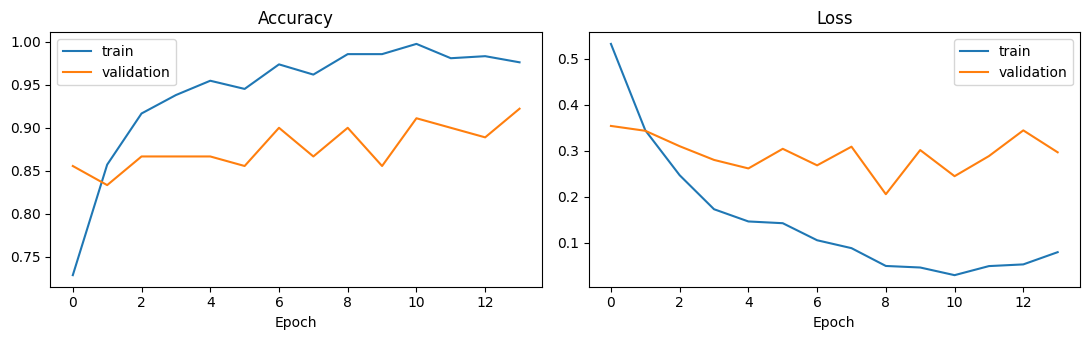

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(history.history["accuracy"], label="train"); ax[0].plot(history.history["val_accuracy"], label="validation")
ax[0].set_title("Accuracy"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(history.history["loss"], label="train"); ax[1].plot(history.history["val_loss"], label="validation")
ax[1].set_title("Loss"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig("training_curves.png", dpi=150); plt.show()

## 7. Test on videos the model has never seen

TEST ACCURACY: 0.956  (90 test videos)

              precision    recall  f1-score   support

Non-violence       1.00      0.91      0.95        45
    Violence       0.92      1.00      0.96        45

    accuracy                           0.96        90
   macro avg       0.96      0.96      0.96        90
weighted avg       0.96      0.96      0.96        90



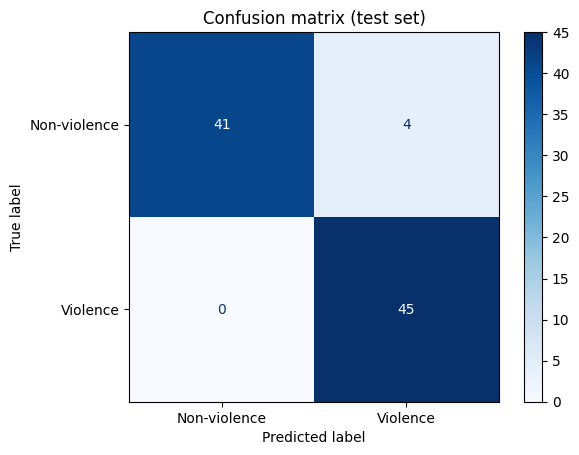

In [16]:
probs = model.predict(X_test, verbose=0).ravel()
preds = (probs >= 0.5).astype(int)
test_acc = (preds == y_test).mean()
print(f"TEST ACCURACY: {test_acc:.3f}  ({len(y_test)} test videos)\n")
print(classification_report(y_test, preds, target_names=["Non-violence", "Violence"]))

cm = confusion_matrix(y_test, preds)
ConfusionMatrixDisplay(cm, display_labels=["Non-violence", "Violence"]).plot(cmap="Blues")
plt.title("Confusion matrix (test set)"); plt.savefig("confusion_matrix.png", dpi=150); plt.show()
model.save("violence_lstm.keras")

## 8. Predict on a single video

In [17]:
def predict_video(path):
    frames = load_frames(path)
    if frames is None:
        print("Could not read this video."); return
    feats = cnn(preprocess_input(frames.copy()), training=False).numpy()
    p = float(model.predict(feats[None], verbose=0)[0][0])
    label = "VIOLENCE" if p >= 0.5 else "NON-VIOLENCE"
    conf = p if p >= 0.5 else 1 - p
    print(f"{os.path.basename(path)} -> {label} (confidence {conf:.0%})")

# Try 5 test videos and compare with the true label
for j in random.sample(range(len(te)), min(5, len(te))):
    predict_video(paths[te[j]])
    print("   true label:", "VIOLENCE" if y_test[j] else "NON-VIOLENCE")

NV_391.mp4 -> NON-VIOLENCE (confidence 99%)
   true label: NON-VIOLENCE
NV_448.mp4 -> NON-VIOLENCE (confidence 100%)
   true label: NON-VIOLENCE
V_424.mp4 -> VIOLENCE (confidence 99%)
   true label: VIOLENCE
NV_215.mp4 -> NON-VIOLENCE (confidence 100%)
   true label: NON-VIOLENCE
V_929.mp4 -> VIOLENCE (confidence 100%)
   true label: VIOLENCE


## 9. Download your results
Run this cell, then upload the downloaded files to your GitHub repo. Your real results (accuracy, confusion matrix, curves) go in the README.

In [18]:
from google.colab import files
for f in ["training_curves.png", "confusion_matrix.png", "violence_lstm.keras"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>